## Preparing the GPS Data for Analysis

In [38]:
import math
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib as mpl
import contextily as ctx
import pandas as pd

### 1 SSC Measurement Campaign

For this campaign, the following data points and transects in the dataset are identified:
1. TESTXXXXXX: continuous measurements of the boat trajectory during the experiment
2. PERFJAGXXXXXX: continuous measurement of the transect between the shore and the measurement equipment
3. GPSXXXXXX: discrete measurements of the position of the measurement equipment and auxiliary materials
    - GPS000001 is the west flagpole
    - GPS000002 is the measurement pyramid
    - GPS000003 is the east flagpole
    - GPS000004 is the cooperating flagpole
    - GPS000005 is the beach

**1.1 Loading the Data**

In [33]:
file_path = r"Pruebas_DELFT_20260929.txt"
# Use the 20260926 filename here if that is the actual file you have.

columns = [
    "point_id",
    "date",
    "time",
    "easting",
    "northing",
    "ellipsoidal_height",
    "geoid_separation",
    "cq_3d",
]

gps = pd.read_csv(
    file_path,
    sep=r"\s+",
    skiprows=1,          # skip the descriptive header
    names=columns,
    dtype={
        "point_id": "string",
        "date": "string",
        "time": "string",
        "easting": "float64",
        "northing": "float64",
        "ellipsoidal_height": "float64",
        "geoid_separation": "float64",
        "cq_3d": "float64",
    },
)

gps["datetime"] = pd.to_datetime(
    gps["date"] + " " + gps["time"],
    format="%m/%d/%Y %H:%M:%S",
)
gps["datetime"] = gps["datetime"] - pd.Timedelta(hours=1)

gps = gps.drop(columns=["date", "time"])

# Determining actual elevations
gps['elevation'] = gps['ellipsoidal_height'] - gps['geoid_separation']

display(gps.head())

,point_id,easting,northing,ellipsoidal_height,geoid_separation,cq_3d,datetime,elevation
0,GPS0001,806688.1680,2.343461e+06,-15.2602,-13.9310,0.0159,2026-09-29 11:18:19,-1.3292
1,GPS0002,806687.4266,2.343459e+06,-15.2558,-13.9309,0.0159,2026-09-29 11:18:40,-1.3249
2,GPS0003,806697.2479,2.343461e+06,-15.3033,-13.9310,0.0177,2026-09-29 11:19:18,-1.3723
3,GPS0004,806687.4149,2.343452e+06,-15.3480,-13.9308,0.0156,2026-09-29 11:19:56,-1.4172
4,GPS0005,806680.4073,2.343383e+06,-14.3263,-13.9294,0.0210,2026-09-29 11:22:42,-0.3969


**1.2 Calculating vessel speed**

In [34]:
# Extract the label from point_id
gps["trajectory"] = gps["point_id"].str.extract(
    r"^([A-Za-z]+)",
    expand=False,
)

test = gps[gps["trajectory"] == "TEST"].sort_values("datetime")
gps_points = gps[gps["trajectory"] == "GPS"].sort_values("datetime")

# Calculate horizontal speed within each trajectory
ordered_gps = gps.sort_values(["trajectory", "datetime"])

delta_easting = ordered_gps.groupby("trajectory")["easting"].diff()
delta_northing = ordered_gps.groupby("trajectory")["northing"].diff()

delta_time = (
    ordered_gps.groupby("trajectory")["datetime"]
    .diff()
    .dt.total_seconds()
)

distance = np.hypot(delta_easting, delta_northing)

# Speed in metres per second
speed_m_s = distance / delta_time.where(delta_time > 0)

# Add the results to the original DataFrame order
gps["speed_m_s"] = speed_m_s.reindex(gps.index)
gps["speed_km_h"] = gps["speed_m_s"] * 3.6

display(
    gps[
        [
            "point_id",
            "trajectory",
            "datetime",
            "speed_m_s",
            "speed_km_h",
        ]
    ]
)


,point_id,trajectory,datetime,speed_m_s,speed_km_h
0,GPS0001,GPS,2026-09-29 11:18:19,NaN,NaN
1,GPS0002,GPS,2026-09-29 11:18:40,0.074992,0.269972
2,GPS0003,GPS,2026-09-29 11:19:18,0.264426,0.951933
3,GPS0004,GPS,2026-09-29 11:19:56,0.362235,1.304045
4,GPS0005,GPS,2026-09-29 11:22:42,0.417235,1.502046
...,...,...,...,...,...
12898,TEST012676,TEST,2026-09-29 11:09:01,0.618595,2.226943
12899,TEST012677,TEST,2026-09-29 11:09:02,0.770201,2.772725
12900,TEST012678,TEST,2026-09-29 11:09:03,0.628138,2.261297
12901,TEST012679,TEST,2026-09-29 11:09:04,0.256624,0.923846


**1.3 Plotting the entire experiment**

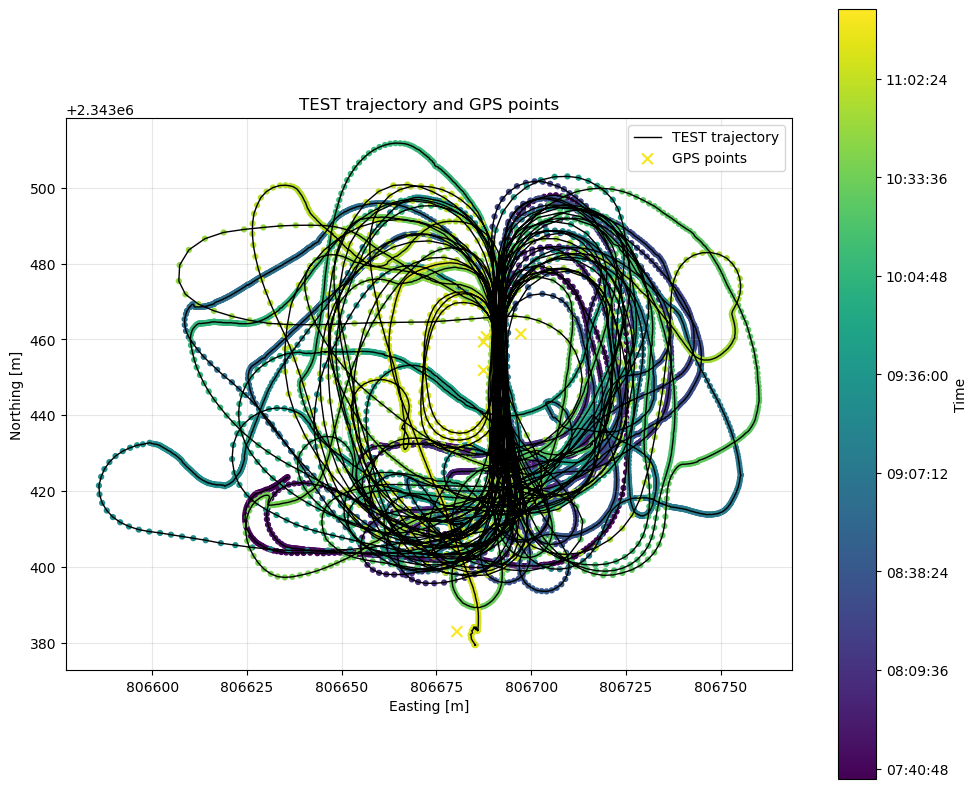

In [35]:
# Use one colour scale for both datasets
plot_data = pd.concat([test, gps_points])
time_values = mdates.date2num(plot_data["datetime"])

norm = mpl.colors.Normalize(
    time_values.min(),
    time_values.max(),
)
cmap = plt.colormaps["viridis"]

fig, ax = plt.subplots(figsize=(10, 8))

# TEST: chronological connected trajectory
ax.plot(
    test["easting"],
    test["northing"],
    color="black",
    linewidth=1,
    label="TEST trajectory",
)

ax.scatter(
    test["easting"],
    test["northing"],
    c=mdates.date2num(test["datetime"]),
    cmap=cmap,
    norm=norm,
    s=12,
)

# GPS: discrete points, not connected
ax.scatter(
    gps_points["easting"],
    gps_points["northing"],
    c=mdates.date2num(gps_points["datetime"]),
    cmap=cmap,
    norm=norm,
    marker="x",
    s=60,
    linewidths=1.5,
    label="GPS points",
)

ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("Easting [m]")
ax.set_ylabel("Northing [m]")
ax.set_title("TEST trajectory and GPS points")
ax.legend()
ax.grid(True, alpha=0.3)

scalar_map = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
scalar_map.set_array([])
colorbar = fig.colorbar(scalar_map, ax=ax)
colorbar.ax.yaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S"))
colorbar.set_label("Time")

plt.tight_layout()
plt.show()

**1.5 Plotting individual passages**

This is done by specifying the exact times of passage for each manoeuvre as recorded during the field experiment. The location at this specific time is interpolated, and a set time frame before and after that passage is plotted.

In [4]:
manoeuvres = {
    "A1-11": "07:40:22",
    "A1-12": "07:46:51",
    "A2-11": "07:57:17",
    "A2-12": "08:02:11",
    "A3-11": "08:07:25",
    "A3-12": "08:12:08",
    "B-11":  "08:17:53",
    "B-12":  "08:23:40",
    "C-11":  "08:40:40",
    "C-12":  "08:45:57",
    "E-11":  "08:51:35",
    "E-12":  "08:57:08",
    
    "A1-21": "09:02:35",
    "A1-22": "09:07:47",
    "A2-21": "09:19:14",
    "A2-22": "09:29:27",
    "A3-21": "09:29:27",
    "A3-22": "09:35:17",
    "B-21":  "09:42:33",
    "B-22":  "09:49:34",
    "C-21":  "09:55:04",
    "C-22":  "09:58:54",
    "E-21":  "10:02:51",
    "E-22":  "10:06:45",

    "A1-31": "10:15:16",
    "A2-31": "10:17:03",
    "A3-31": "10:19:05",
    "B-31":  "10:22:36",
    "C-31":  "10:25:25",
    "E-31":  "10:31:33",
    "D-31":  "10:37:55",
    "D-32":  "10:41:15",
    "D-33":  "10:44:33",
    "F-31":  "10:49:06", #time of 3rd pass 
    "F-32":  "10:53:57", #time of 3rd pass
    "F-33":  "11:00:27", #time of 3rd pass

    "A1-41": "07:52:21",
    "B-41":  "08:29:40",
    "B-42":  "08:36:05",
    "A2-41": "09:24:16",
    "E-41": "10:10:30",
    "C-41": "10:28:22",
    "A1-42": "10:34:17",
    "F-41": "11:05:41"  

}

In [ ]:
# Plotting individual manoeuvres

manoeuvre_date = "2026-09-29"

for manoeuvre_name, manoeuvre_time in manoeuvres.items():
    manoeuvre_datetime = pd.to_datetime(
        f"{manoeuvre_date} {manoeuvre_time}",
        format="%Y-%m-%d %H:%M:%S",
    )

    start_time = manoeuvre_datetime - pd.Timedelta(minutes=2)
    end_time = manoeuvre_datetime + pd.Timedelta(minutes=2)

    time_window = gps[
        gps["datetime"].between(start_time, end_time)
    ].copy()

    test_window = time_window[
        time_window["trajectory"] == "TEST"
    ].sort_values("datetime")

    if time_window.empty:
        print(f"No data found for {manoeuvre_name} at {manoeuvre_time}")
        continue

    time_values = mdates.date2num(time_window["datetime"])
    norm = mpl.colors.Normalize(
        time_values.min(),
        time_values.max(),
    )
    cmap = plt.colormaps["viridis"]

    fig, ax = plt.subplots(figsize=(10, 8))

    if not test_window.empty:
        ax.plot(
            test_window["easting"],
            test_window["northing"],
            color="black",
            linewidth=1,
            label="TEST trajectory",
        )

        ax.scatter(
            test_window["easting"],
            test_window["northing"],
            c=mdates.date2num(test_window["datetime"]),
            cmap=cmap,
            norm=norm,
            s=15,
        )

        # Interpolate the TEST position at the exact manoeuvre time.
        test_timestamps = test_window["datetime"].astype("int64")
        manoeuvre_timestamp = manoeuvre_datetime.value

        if (
            manoeuvre_timestamp >= test_timestamps.min()
            and manoeuvre_timestamp <= test_timestamps.max()
        ):
            manoeuvre_easting = np.interp(
                manoeuvre_timestamp,
                test_timestamps,
                test_window["easting"],
            )
            manoeuvre_northing = np.interp(
                manoeuvre_timestamp,
                test_timestamps,
                test_window["northing"],
            )

            ax.scatter(
                manoeuvre_easting,
                manoeuvre_northing,
                color="red",
                marker="x",
                s=100,
                linewidths=2,
                zorder=5,
                label=f"{manoeuvre_name} time",
            )

    # GPS measurements are discrete points and are not connected.
    ax.scatter(
        gps_points["easting"],
        gps_points["northing"],
        c=mdates.date2num(gps_points["datetime"]),
        cmap=cmap,
        norm=norm,
        marker="x",
        s=70,
        linewidths=1.5,
        label="GPS points",
        )

    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("Easting [m]")
    ax.set_ylabel("Northing [m]")
    ax.set_title(
        f"{manoeuvre_name}: {manoeuvre_datetime:%Y-%m-%d %H:%M:%S}"
    )
    ax.legend()
    ax.grid(True, alpha=0.3)

    scalar_map = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
    scalar_map.set_array([])

    colorbar = fig.colorbar(scalar_map, ax=ax)
    colorbar.ax.yaxis.set_major_formatter(
        mdates.DateFormatter("%H:%M:%S")
    )
    colorbar.set_label("Time")

    plt.tight_layout()
    plt.show()

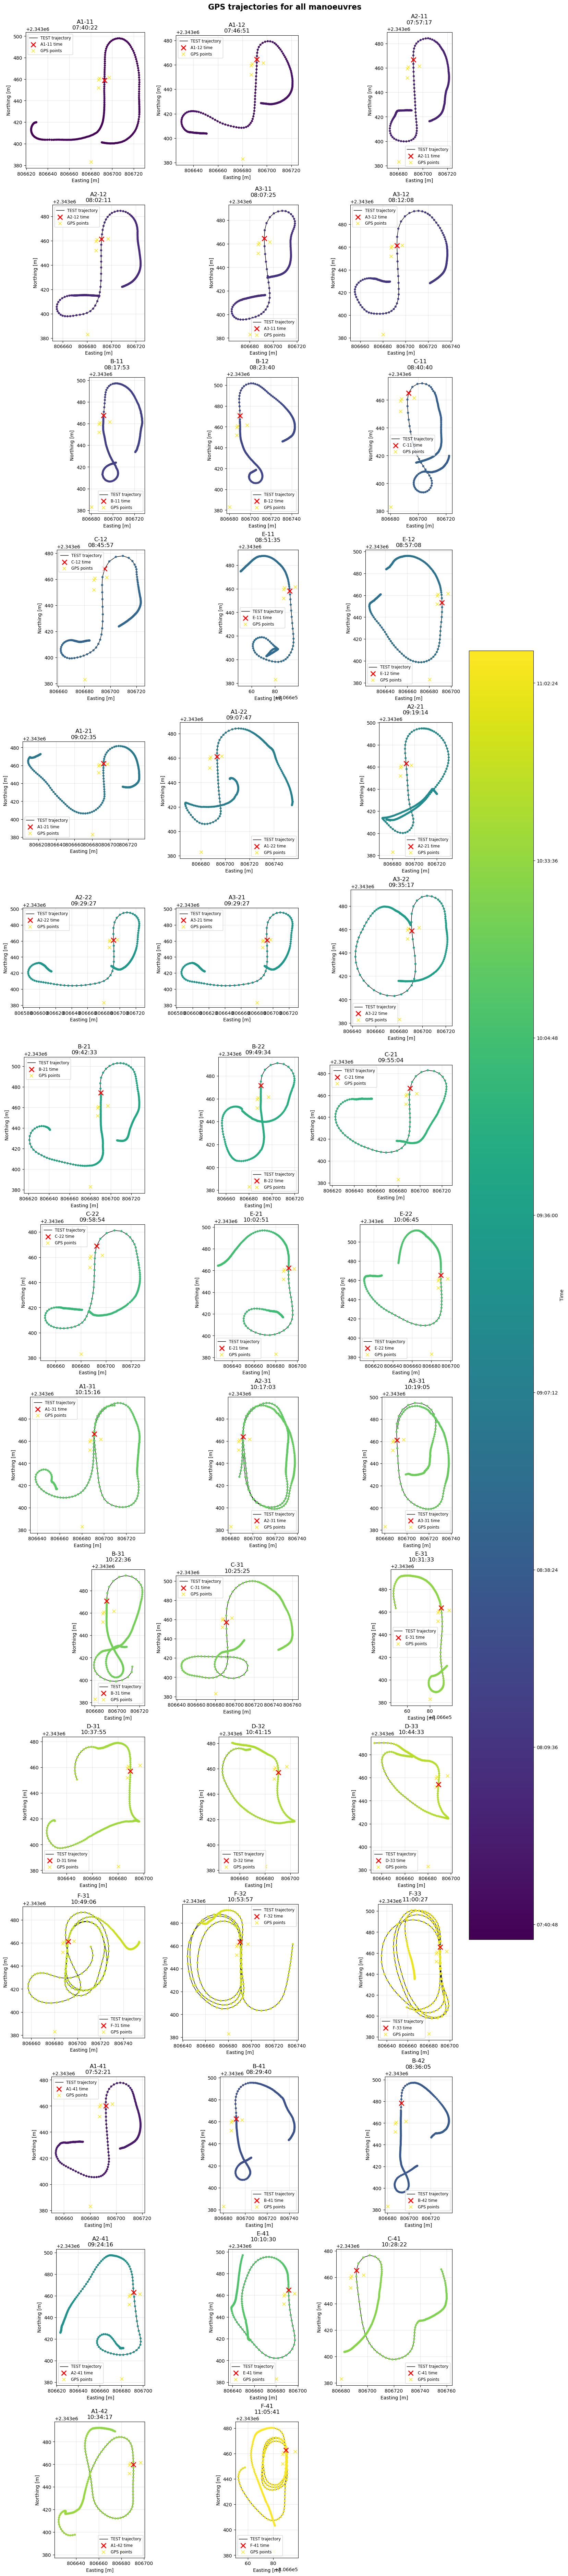

In [36]:
manoeuvre_date = "2026-09-29"

# Prepare the data for every manoeuvre first
manoeuvre_windows = []

for manoeuvre_name, manoeuvre_time in manoeuvres.items():
    manoeuvre_datetime = pd.to_datetime(
        f"{manoeuvre_date} {manoeuvre_time}",
        format="%Y-%m-%d %H:%M:%S",
    )

    start_time = manoeuvre_datetime - pd.Timedelta(minutes=2)
    end_time = manoeuvre_datetime + pd.Timedelta(minutes=2)

    time_window = gps[
        gps["datetime"].between(start_time, end_time)
    ].copy()

    if time_window.empty:
        print(f"No data found for {manoeuvre_name} at {manoeuvre_time}")
        continue

    test_window = time_window[
        time_window["trajectory"] == "TEST"
    ].sort_values("datetime")

    manoeuvre_windows.append(
        {
            "name": manoeuvre_name,
            "datetime": manoeuvre_datetime,
            "time_window": time_window,
            "test_window": test_window,
        }
    )

if not manoeuvre_windows:
    raise ValueError("No manoeuvre windows contain GPS data.")

# Use one common colour scale for all panels
all_time_values = np.concatenate(
    [
        mdates.date2num(window["time_window"]["datetime"])
        for window in manoeuvre_windows
    ]
)

norm = mpl.colors.Normalize(
    vmin=all_time_values.min(),
    vmax=all_time_values.max(),
)

cmap = plt.colormaps["viridis"]

# Three columns, with enough rows for all manoeuvres
ncols = 3
nrows = math.ceil(len(manoeuvre_windows) / ncols)

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(5.5 * ncols, 5 * nrows),
    squeeze=False,
    constrained_layout=True,
)

axes = axes.ravel()

for ax, window in zip(axes, manoeuvre_windows):
    manoeuvre_name = window["name"]
    manoeuvre_datetime = window["datetime"]
    test_window = window["test_window"]

    # TEST trajectory
    if not test_window.empty:
        ax.plot(
            test_window["easting"],
            test_window["northing"],
            color="black",
            linewidth=1,
            label="TEST trajectory",
            zorder=2,
        )

        ax.scatter(
            test_window["easting"],
            test_window["northing"],
            c=mdates.date2num(test_window["datetime"]),
            cmap=cmap,
            norm=norm,
            s=12,
            zorder=3,
        )

        # Interpolate TEST position at the exact manoeuvre time
        test_timestamps = test_window["datetime"].astype("int64")
        manoeuvre_timestamp = manoeuvre_datetime.value

        if (
            manoeuvre_timestamp >= test_timestamps.min()
            and manoeuvre_timestamp <= test_timestamps.max()
        ):
            manoeuvre_easting = np.interp(
                manoeuvre_timestamp,
                test_timestamps,
                test_window["easting"],
            )

            manoeuvre_northing = np.interp(
                manoeuvre_timestamp,
                test_timestamps,
                test_window["northing"],
            )

            ax.scatter(
                manoeuvre_easting,
                manoeuvre_northing,
                color="red",
                marker="x",
                s=100,
                linewidths=2,
                label=f"{manoeuvre_name} time",
                zorder=5,
            )

    # Discrete GPS measurements
    ax.scatter(
        gps_points["easting"],
        gps_points["northing"],
        c=mdates.date2num(gps_points["datetime"]),
        cmap=cmap,
        norm=norm,
        marker="x",
        s=45,
        linewidths=1.2,
        label="GPS points",
        zorder=4,
    )

    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("Easting [m]")
    ax.set_ylabel("Northing [m]")
    ax.set_title(
        f"{manoeuvre_name}\n"
        f"{manoeuvre_datetime:%H:%M:%S}"
    )
    ax.grid(True, alpha=0.3)

    # Avoid repeating a large legend in every panel
    ax.legend(fontsize="small", loc="best")

# Hide unused axes in the final row
for ax in axes[len(manoeuvre_windows):]:
    ax.set_visible(False)

# One colourbar for the complete figure
scalar_map = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
scalar_map.set_array([])

colorbar = fig.colorbar(
    scalar_map,
    ax=axes[:len(manoeuvre_windows)].tolist(),
    shrink=0.85,
    pad=0.02,
)

colorbar.ax.yaxis.set_major_formatter(
    mdates.DateFormatter("%H:%M:%S")
)
colorbar.set_label("Time")

fig.suptitle(
    "GPS trajectories for all manoeuvres",
    fontsize=16,
    fontweight="bold",
)

plt.show()

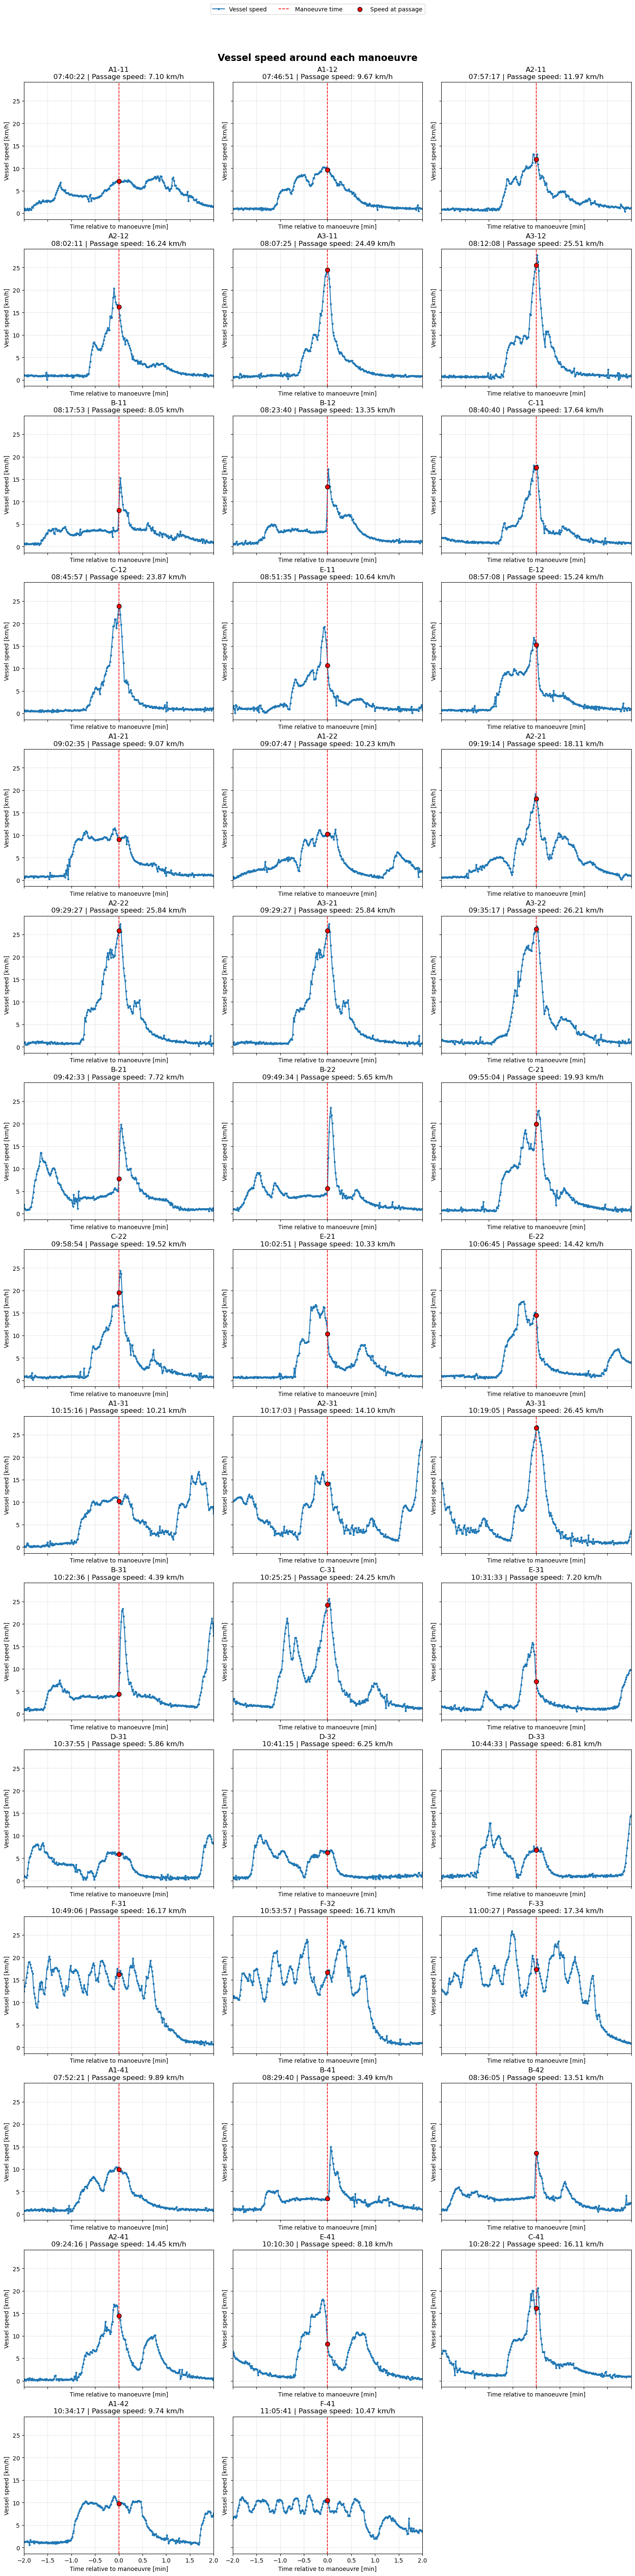

In [50]:
manoeuvre_date = "2026-09-29"

window_before = pd.Timedelta(minutes=2)
window_after = pd.Timedelta(minutes=2)

speed_windows = []

for manoeuvre_name, manoeuvre_time in manoeuvres.items():
    manoeuvre_datetime = pd.to_datetime(
        f"{manoeuvre_date} {manoeuvre_time}",
        format="%Y-%m-%d %H:%M:%S",
    )

    start_time = manoeuvre_datetime - window_before
    end_time = manoeuvre_datetime + window_after

    speed_window = gps[
        (gps["trajectory"] == "TEST")
        & gps["datetime"].between(start_time, end_time)
    ].copy()

    if speed_window.empty:
        print(f"No TEST speed data found for {manoeuvre_name}")
        continue

    speed_window = speed_window.sort_values("datetime")

    # Only valid speeds can be used for interpolation
    valid_speed = speed_window.dropna(
        subset=["speed_km_h"]
    ).copy()

    if valid_speed.empty:
        print(f"No valid speed data found for {manoeuvre_name}")
        continue

    # Time relative to the manoeuvre, in minutes
    speed_window["relative_time_min"] = (
        speed_window["datetime"] - manoeuvre_datetime
    ).dt.total_seconds() / 60

    # Time relative to the manoeuvre, in seconds
    relative_seconds = (
        valid_speed["datetime"] - manoeuvre_datetime
    ).dt.total_seconds()

    # Interpolate only if the passage is bracketed by valid data
    if relative_seconds.min() <= 0 <= relative_seconds.max():
        speed_at_passage = np.interp(
            0,
            relative_seconds.to_numpy(),
            valid_speed["speed_km_h"].to_numpy(),
        )
        speed_text = f"{speed_at_passage:.2f} km/h"
    else:
        speed_at_passage = np.nan
        speed_text = "unavailable"

    speed_windows.append(
        {
            "name": manoeuvre_name,
            "datetime": manoeuvre_datetime,
            "data": speed_window,
            "speed_at_passage": speed_at_passage,
            "speed_text": speed_text,
        }
    )

if not speed_windows:
    raise ValueError("No manoeuvre windows contain valid TEST speed data.")

# Configure the compact layout
ncols = 3
nrows = math.ceil(len(speed_windows) / ncols)

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(5 * ncols, 4 * nrows),
    sharex=True,
    sharey=True,
    squeeze=False,
    constrained_layout=True,
)

axes = axes.ravel()

for ax, window in zip(axes, speed_windows):
    speed_window = window["data"]
    speed_at_passage = window["speed_at_passage"]

    ax.plot(
        speed_window["relative_time_min"],
        speed_window["speed_km_h"],
        color="tab:blue",
        linewidth=1.5,
        marker="o",
        markersize=2.5,
        label="Vessel speed",
    )

    # Mark the passage time
    ax.axvline(
        0,
        color="red",
        linestyle="--",
        linewidth=1.2,
        label="Manoeuvre time",
    )

    # Mark the interpolated speed at passage
    if not np.isnan(speed_at_passage):
        ax.scatter(
            0,
            speed_at_passage,
            color="red",
            edgecolor="black",
            s=55,
            zorder=5,
            label="Speed at passage",
        )

    ax.set_xlim(-2, 2)
    ax.set_xlabel("Time relative to manoeuvre [min]")
    ax.set_ylabel("Vessel speed [km/h]")
    ax.set_title(
        f"{window['name']}\n"
        f"{window['datetime']:%H:%M:%S} | "
        f"Passage speed: {window['speed_text']}"
    )
    ax.grid(True, alpha=0.3)

# Hide unused axes in the last row
for ax in axes[len(speed_windows):]:
    ax.set_visible(False)

# Create one shared legend
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=3,
    bbox_to_anchor=(0.5, 1.02),
)

fig.suptitle(
    "Vessel speed around each manoeuvre",
    fontsize=16,
    fontweight="bold",
)

plt.show()

In [ ]:
# Plotting vessel speed during each manoeuvre

manoeuvre_date = "2026-09-29"

window_before = pd.Timedelta(minutes=2)
window_after = pd.Timedelta(minutes=2)

for manoeuvre_name, manoeuvre_time in manoeuvres.items():
    manoeuvre_datetime = pd.to_datetime(
        f"{manoeuvre_date} {manoeuvre_time}",
        format="%Y-%m-%d %H:%M:%S",
    )

    start_time = manoeuvre_datetime - window_before
    end_time = manoeuvre_datetime + window_after

    # Use TEST data because this is where vessel speed was calculated
    speed_window = gps[
        (gps["trajectory"] == "TEST")
        & gps["datetime"].between(start_time, end_time)
    ].copy()

    if speed_window.empty:
        print(f"No TEST speed data found for {manoeuvre_name}")
        continue

    speed_window = speed_window.sort_values("datetime")

    # Remove missing speed values before interpolation
    valid_speed = speed_window.dropna(
        subset=["speed_km_h"]
    ).copy()

    if valid_speed.empty:
        print(f"No valid speed data found for {manoeuvre_name}")
        continue

    # Convert timestamps to seconds for interpolation
    time_seconds = (
        valid_speed["datetime"] - manoeuvre_datetime
    ).dt.total_seconds()

    manoeuvre_time_seconds = 0.0

    # Interpolate only if the manoeuvre time is bracketed
    # by available speed measurements
    if (
        time_seconds.min()
        <= manoeuvre_time_seconds
        <= time_seconds.max()
    ):
        speed_at_manoeuvre = np.interp(
            manoeuvre_time_seconds,
            time_seconds.to_numpy(),
            valid_speed["speed_km_h"].to_numpy(),
        )
        speed_text = f"{speed_at_manoeuvre:.2f} km/h"
    else:
        speed_at_manoeuvre = np.nan
        speed_text = "unavailable"

    # Time relative to the manoeuvre, in minutes
    speed_window["relative_time_min"] = (
        speed_window["datetime"] - manoeuvre_datetime
    ).dt.total_seconds() / 60

    fig, ax = plt.subplots(figsize=(10, 6))

    ax.plot(
        speed_window["relative_time_min"],
        speed_window["speed_km_h"],
        color="tab:blue",
        linewidth=1.5,
        marker="o",
        markersize=3,
        label="Vessel speed",
    )

    # Mark the manoeuvre time
    ax.axvline(
        0,
        color="red",
        linestyle="--",
        linewidth=1.5,
        label="Moment of passing",
    )

    # Mark the interpolated speed at the manoeuvre
    if not np.isnan(speed_at_manoeuvre):
        ax.scatter(
            0,
            speed_at_manoeuvre,
            color="red",
            edgecolor="black",
            s=70,
            zorder=5,
        )

    ax.set_xlim(-2, 2)
    ax.set_xlabel("Time relative to manoeuvre [min]")
    ax.set_ylabel("Vessel speed [km/h]")

    ax.set_title(
        f"{manoeuvre_name} — vessel speed\n"
        f"{manoeuvre_datetime:%Y-%m-%d %H:%M:%S} | "
        f"Speed at passage: {speed_text}"
    )

    ax.grid(True, alpha=0.3)
    ax.legend()

    plt.tight_layout()
    plt.show()

**1.6 Preparing and visualising the transect**

In [31]:
transect = gps[gps['trajectory'] == 'PERFJAG']

# Calculate incremental horizontal distances using the Pythagorean theorem
dx = transect['easting'].diff().fillna(0)
dy = transect['northing'].diff().fillna(0)
incremental_distance = np.sqrt(dx**2 + dy**2)

#Compute cumulative distance along the transect line
transect['cumulative_distance'] = incremental_distance.cumsum()
transect['cumulative_distance'] = transect['cumulative_distance'] - transect['cumulative_distance'].iloc[-1]

C:\Users\raoul\AppData\Local\Temp\ipykernel_34256\1801926571.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  transect['cumulative_distance'] = incremental_distance.cumsum()
C:\Users\raoul\AppData\Local\Temp\ipykernel_34256\1801926571.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  transect['cumulative_distance'] = transect['cumulative_distance'] - transect['cumulative_distance'].iloc[-1]


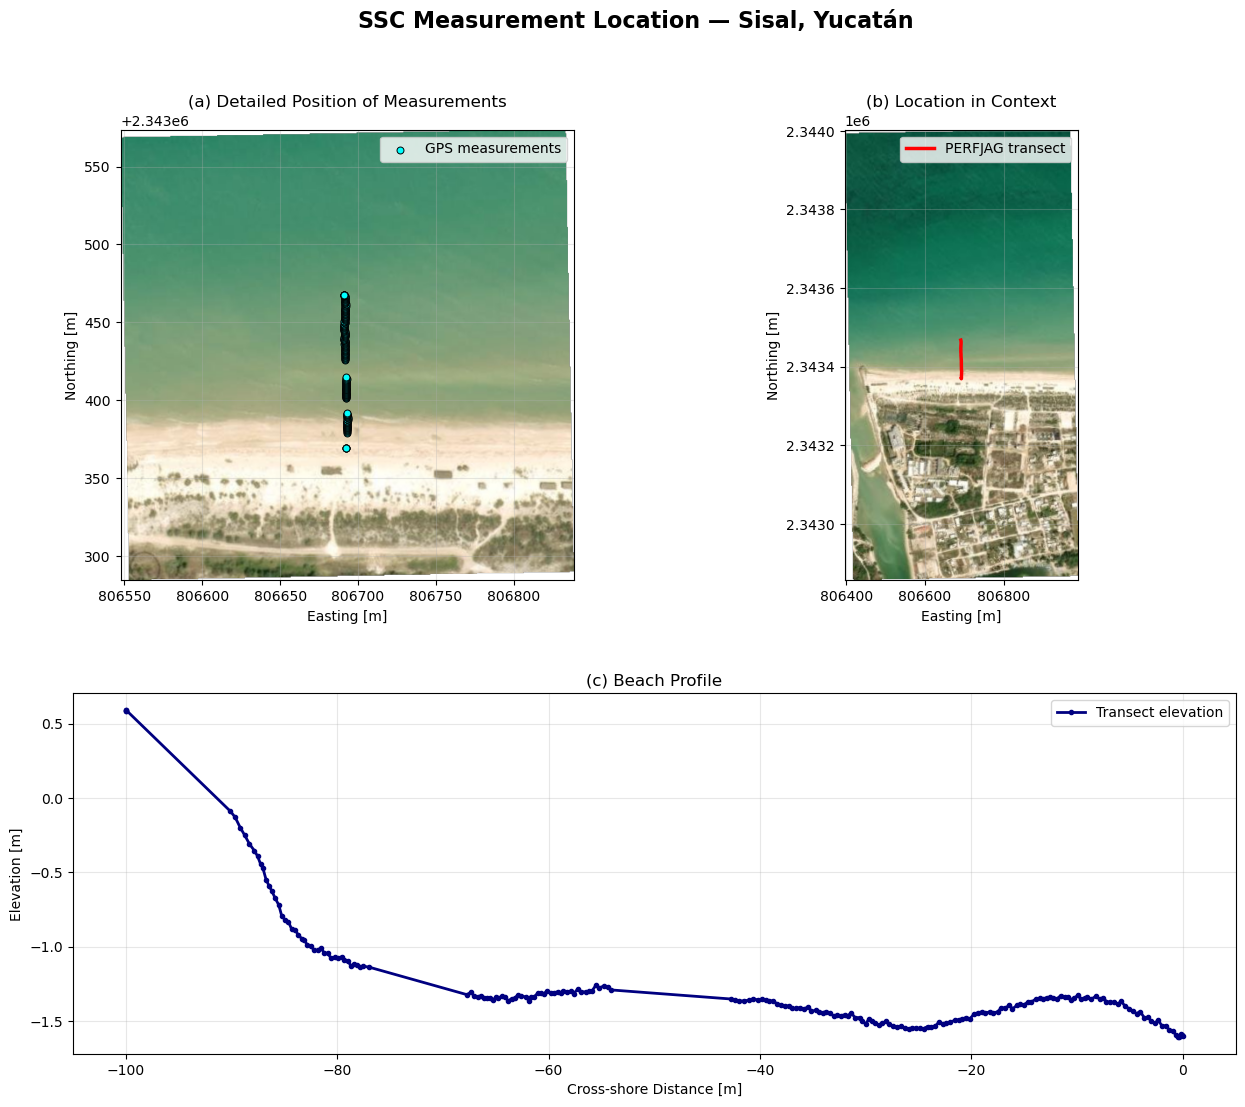

In [32]:
import matplotlib.pyplot as plt
import contextily as ctx

gps_crs = "EPSG:32615"

x = transect["easting"]
y = transect["northing"]

# Map extent around the GPS transect
padding = 30

xmin = x.min() - padding
xmax = x.max() + padding
ymin = y.min() - padding
ymax = y.max() + padding

# Create a 2-by-2 layout.
# The bottom axis will span both columns.
fig = plt.figure(figsize=(15, 12))
gs = fig.add_gridspec(
    nrows=2,
    ncols=2,
    height_ratios=[1, 0.8],
    hspace=0.28,
    wspace=0.12,
)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[1, :])

# ------------------------------------------------------------
# Top-left: detailed aerial view
# ------------------------------------------------------------

ax1.set_xlim(xmin, xmax)
ax1.set_ylim(ymin, ymax)

ctx.add_basemap(
    ax1,
    source=ctx.providers.Esri.WorldImagery,
    crs=gps_crs,
    zoom=18,
    reset_extent=False,
    attribution=False,
)

ax1.scatter(
    x,
    y,
    color="cyan",
    edgecolors="black",
    linewidths=0.7,
    s=25,
    zorder=11,
    label="GPS measurements",
)

ax1.set_aspect("equal", adjustable="box")
ax1.set_xlabel("Easting [m]")
ax1.set_ylabel("Northing [m]")
ax1.set_title("(a) Detailed Position of Measurements")
ax1.legend(loc="best")
ax1.grid(True, alpha=0.3)

# ------------------------------------------------------------
# Top-right: wider aerial view
# ------------------------------------------------------------

ax2.set_xlim(xmin, xmax)
ax2.set_ylim(ymin, ymax)

ctx.add_basemap(
    ax2,
    source=ctx.providers.Esri.WorldImagery,
    crs=gps_crs,
    zoom=16,
    reset_extent=False,
    attribution=False,
)

ax2.plot(
    x,
    y,
    color="red",
    linewidth=2.5,
    zorder=10,
    label="PERFJAG transect",
)

ax2.set_aspect("equal", adjustable="box")
ax2.set_xlabel("Easting [m]")
ax2.set_ylabel("Northing [m]")
ax2.set_title("(b) Location in Context")
ax2.legend(loc="best")
ax2.grid(True, alpha=0.3)

# ------------------------------------------------------------
# Bottom: actual transect profile
# ------------------------------------------------------------

ax3.plot(
    transect["cumulative_distance"],
    transect["elevation"],
    color="navy",
    linewidth=2,
    marker="o",
    markersize=3,
    label="Transect elevation",
)

ax3.set_title("(c) Beach Profile")
ax3.set_xlabel("Cross-shore Distance [m]")
ax3.set_ylabel("Elevation [m]")
ax3.grid(True, alpha=0.3)
ax3.legend(loc="best")

fig.suptitle(
    "SSC Measurement Location — Sisal, Yucatán",
    fontsize=16,
    fontweight="bold",
)

plt.show()